# Task 1 · Find Where the Image Changes (20 marks)

ES666 Assignment 3 · Lunar Landing: The Final Descent. The full assignment is
in the handout, `ES666_A3_Handout.pdf`, and in `tasks.md`.

Learn how motion is written into image intensities: compute image gradients,
connect them to motion, and find the points that can be tracked. Images are
arrays indexed `image[y, x]` (y is the row, x the column); points are `[x, y]`.
Do not use `np.gradient`.

**How this notebook works**

* Write your code only in the cells whose first line starts with `# YOUR CODE`.
  Only those cells are graded, and they are read from the **saved** notebook.
  Add your own cells anywhere for experiments or notes: they are never graded.
  A helper function you want graded with your code goes in a `# YOUR CODE` cell
  (a new cell whose first line is `# YOUR CODE` works too).
* Run the `check(...)` cell after your code: it tests your functions and prints
  PASS or FAIL for each test.
* Answer each question in the cell right below it, in one or two sentences,
  replacing *TODO*.
* Save often (Ctrl+S). Before you submit, run everything from a clean start:
  restart the kernel and run all cells, or run `python run_notebooks.py`.

**Name:** Haarit

**Roll number:** 23110077

In [5]:
# PROVIDED: run this cell first
%matplotlib inline
import numpy as np
from provided.notebook import check
from provided.task1.steps import check_constraint, load_task_frame, show_features, show_gradients

frame = load_task_frame()          # frame 276 of the descent, at quarter size

frame 276, scale 0.25, shape (432, 588)


## 1.1 Spatial gradients (6 marks)

Implement central differences, without `np.gradient`:

$$
I_x(x,y)=\frac{I(x+1,y)-I(x-1,y)}{2},\qquad I_y(x,y)=\frac{I(x,y+1)-I(x,y-1)}{2}.
$$

In [6]:
# YOUR CODE: Task 1.1

def spatial_gradients(image):
    """Central differences, equation (1.1):
        Ix(x, y) = (I(x+1, y) - I(x-1, y)) / 2,   Iy(x, y) = (I(x, y+1) - I(x, y-1)) / 2

    Returns (ix, iy): float arrays shaped like image, 0 on the one-pixel border.

    How to write it (no loops needed):
      1. image = image.astype(np.float64); start from ix = np.zeros_like(image).
      2. image[1:-1, 2:] - image[1:-1, :-2] is I(x+1) - I(x-1) for every inner
         pixel: halve it and store it in ix[1:-1, 1:-1], so the whole border stays 0.
      3. Do the same with the neighbours above and below,
         image[2:, 1:-1] - image[:-2, 1:-1], for iy[1:-1, 1:-1].
    """
    image = image.astype(np.float64)
    ix = np.zeros_like(image)
    iy = np.zeros_like(image)
    ix[1:-1, 1:-1] = (image[1:-1, 2:] - image[1:-1, :-2]) / 2
    iy[1:-1, 1:-1] = (image[2:, 1:-1] - image[:-2, 1:-1]) / 2
    return ix, iy

In [7]:
check("1.1")

Task 1.1 checks
  PASS  spatial gradients of a ramp
  PASS  spatial gradients border is zero
  PASS  x is columns and y is rows
3 of 3 passed


True

  saved outputs/task1/gradients.png


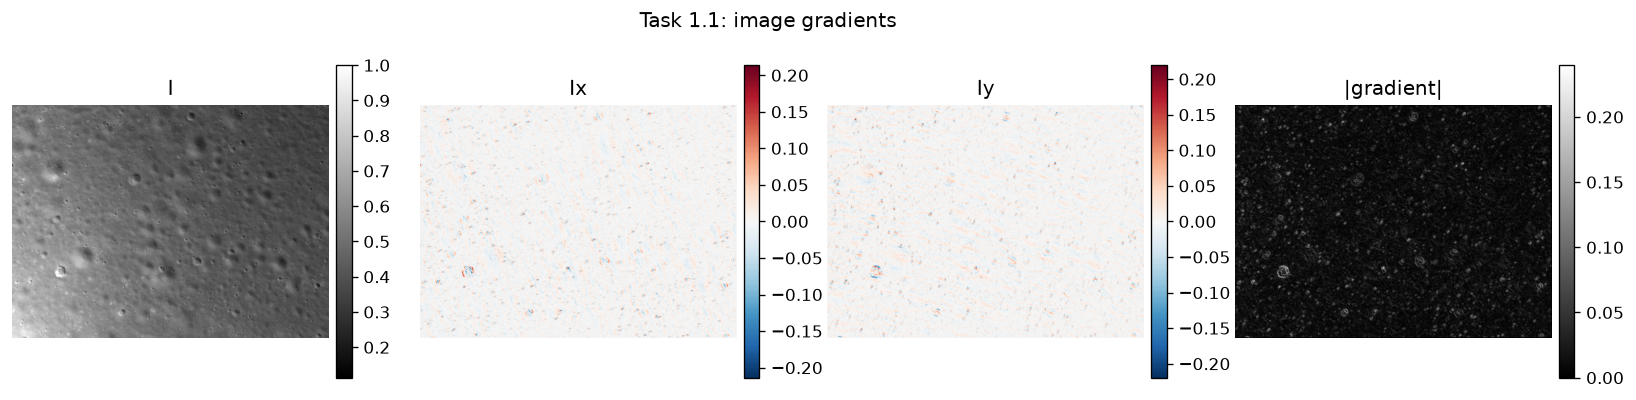

In [8]:
grad = show_gradients(frame, spatial_gradients)

**(a)** Where are the gradients strongest, and where are they weakest?

Gradients are stongest around the craters (irregular surface) and weakest on plain surface.

## 1.2 Temporal change and motion (5 marks)

Implement $I_t = I_1 - I_0$. For a small motion $(u, v)$, brightness constancy
gives the motion constraint

$$
I_x u + I_y v + I_t \approx 0.
$$

The provided cell checks it on frame 276 shifted by a known $(u, v) = (0.3, -0.2)$.

In [9]:
# YOUR CODE: Task 1.2

def temporal_difference(image0, image1):
    """It = I1 - I0 (Task 1.2): how much each pixel's brightness changed.

    Returns a float array shaped like image0.

    Hint: convert both images with .astype(np.float64) before subtracting, so
    integer images cannot wrap around.
    """
    # TODO
    image0 = image0.astype(np.float64)
    image1 = image1.astype(np.float64)
    return image1 - image0

In [10]:
check("1.2")

Task 1.2 checks
  PASS  temporal difference of identical images is zero
  PASS  temporal difference is image1 minus image0
  PASS  motion constraint holds for a known shift
3 of 3 passed


True

  motion constraint on a synthetic shift (0.3, -0.2): mean |residual| 0.0042, max 0.1062
  saved outputs/task1/constraint_check.json
  saved outputs/task1/constraint.png


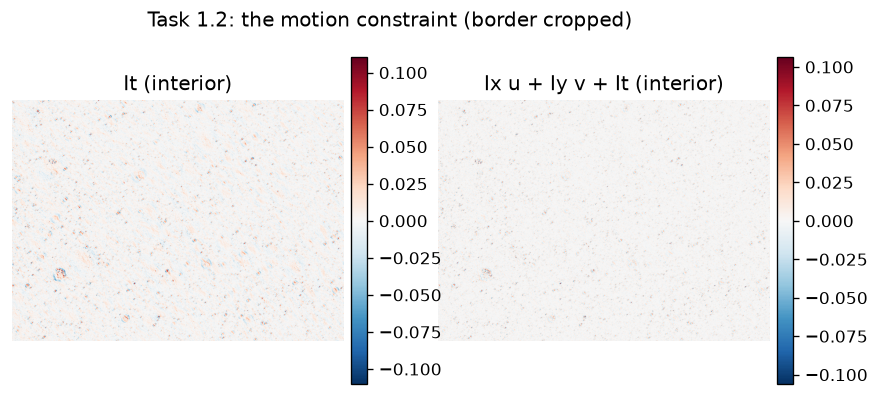

In [11]:
stats = check_constraint(frame, spatial_gradients, temporal_difference)

**(a)** What mean residual does the check report (saved in `constraint_check.json`)?

Mean abosolute residual : 0.004237167080272491

**(b)** Why can one pixel not give both $u$ and $v$?

One pixel gives an equation with two variables (u,v) which is a under - determined system and hence not enough to find both the variables

## 1.3 Choosing good points to track (9 marks)

For each local window build $G = A^TA$, with one row $[I_x, I_y]$ of $A$ per
pixel, and use the smaller eigenvalue as a trackability score:

$$
G = A^TA, \qquad q(x,y)=\min(\lambda_1,\lambda_2).
$$

Select strong points with a minimum separation. The same matrix $G$ is what
Lucas-Kanade solves in Task 2.

In [15]:
# YOUR CODE: Task 1.3

def structure_tensor(ix, iy, x, y, window_radius):
    """G = A^T A for the window centred on pixel (x, y), equation (1.3).

    The window is rows y-r..y+r and columns x-r..x+r, with r = window_radius.
    Returns the 2x2 array [[sum Ix*Ix, sum Ix*Iy], [sum Ix*Iy, sum Iy*Iy]].

    How to write it:
      1. Cut the windows: wx = ix[y - r:y + r + 1, x - r:x + r + 1], and wy from iy.
      2. Sum the element-wise products (np.sum(wx * wx), ...) into a 2x2 np.array.
    """
    # TODO
    wx = ix[y - window_radius:y+window_radius + 1,x - window_radius:x+window_radius+1]
    wy = iy[y - window_radius:y+window_radius + 1,x-window_radius:x+window_radius+1]
    G = np.array([[np.sum(wx*wx), np.sum(wx*wy)], [np.sum(wx*wy), np.sum(wy*wy)]])
    return G


def feature_score(G):
    """Trackability q = min(lambda1, lambda2) of the 2x2 matrix G, equation (1.3).

    Hint: np.linalg.eigvalsh(G) returns the eigenvalues of a symmetric matrix in
    ascending order, so q is its first element. Return it as a float.
    """
    # TODO
    eigenvalues = np.linalg.eigvalsh(G)
    return min(eigenvalues[0],eigenvalues[1])

def compute_window_sums(I, r):
    """Helper function: Computes the sum of a window radius r for every pixel using an integral image."""
    # 1. Create the integral image (Summed Area Table)
    S = np.cumsum(np.cumsum(I, axis=0), axis=1)
    
    # Pad with zeros at the top and left by 1 pixel to handle the math for the top/left edges
    S_pad = np.pad(S, ((1, 0), (1, 0)), mode='constant')
    
    H, W = I.shape
    sums = np.zeros_like(I)
    
    # 2. Vectorized calculation for all valid center pixels at once
    # For a center (y,x), the window is y-r to y+r, and x-r to x+r.
    # In the padded integral image, the 4 corners for the sum are:
    sums[r:H-r, r:W-r] = (
        S_pad[2*r+1:H+1, 2*r+1:W+1]   # Bottom-right
      - S_pad[0:H-2*r,   2*r+1:W+1]   # Top-right (subtracted)
      - S_pad[2*r+1:H+1, 0:W-2*r]     # Bottom-left (subtracted)
      + S_pad[0:H-2*r,   0:W-2*r]     # Top-left (added back because it was subtracted twice)
    )
    return sums


def select_features(image, max_points=200, window_radius=3, min_distance=10, threshold=None):
    """Choose up to max_points strong, well-separated points in an image.

    Returns an (N, 2) float array of [x, y], strongest first, N <= max_points.

    How to write it:
      1. ix, iy = spatial_gradients(image).
      2. Score every pixel whose window fits inside the image (r <= x < W - r and
         r <= y < H - r, r = window_radius) with
         feature_score(structure_tensor(ix, iy, x, y, r)).
      3. Keep scores >= threshold if one is given; otherwise drop scores of 0
         (flat areas).
      4. Sort strongest first: order = np.argsort(-scores).
      5. Walk through that order and keep a point only if it is at least
         min_distance from every point kept so far; stop at max_points.

    Speed: Task 4 calls this about 570 times (once per frame pair and tracker).
    A Python loop over every pixel takes about 5 s per frame, which adds about
    45 minutes to Task 4. Start with the loop if you like, then, before Task 4,
    score all windows at once: sum Ix*Ix, Ix*Iy and Iy*Iy over every window with
    an integral image (np.cumsum along both axes), and use the closed form of the
    smaller eigenvalue of [[a, b], [b, c]]: (a + c) / 2 - sqrt(((a - c) / 2)**2 + b**2).
    """
    ix, iy = spatial_gradients(image)
    H, W = image.shape
    r = window_radius
    
    # 1. Compute element-wise products for the whole image instantly
    ix2 = ix * ix
    iy2 = iy * iy
    ixy = ix * iy
    
    # 2. Sum them over the windows using our fast integral image helper
    sum_ix2 = compute_window_sums(ix2, r)
    sum_iy2 = compute_window_sums(iy2, r)
    sum_ixy = compute_window_sums(ixy, r)
    
    # 3. Calculate the smaller eigenvalue 'q' for the entire image at once 
    # using the closed-form formula from the docstring: (a + c)/2 - sqrt(((a - c)/2)^2 + b^2)
    a = sum_ix2
    b = sum_ixy
    c = sum_iy2
    
    scores = (a + c) / 2.0 - np.sqrt(((a - c) / 2.0)**2 + b**2)
    
    # Flatten the arrays so we can easily filter and sort them
    scores_flat = scores.flatten()
    
    # 4. Drop flat areas (or apply threshold)
    if threshold is not None:
        valid_mask = scores_flat >= threshold
    else:
        valid_mask = scores_flat > 0
        
    valid_indices = np.where(valid_mask)[0]
    # print(valid_indices)
    valid_scores = scores_flat[valid_indices]
    
    # 5. Sort strongest first
    sorted_order = np.argsort(-valid_scores)
    sorted_indices = valid_indices[sorted_order]
    
    # Convert flat indices back to (y, x) coordinates
    y_coords, x_coords = np.unravel_index(sorted_indices, (H, W))
    
    # 6. Non-Maximum Suppression (Distance check)
    kept_points = []
    
    for i in range(len(sorted_indices)):
        x, y = x_coords[i], y_coords[i]
        
        # Discard points too close to the border
        if x < r or x >= W - r or y < r or y >= H - r:
            continue
            
        if kept_points:
            pts = np.array(kept_points)
            distances = np.sqrt((pts[:, 0] - x)**2 + (pts[:, 1] - y)**2)
            if np.any(distances < min_distance):
                continue
                
        kept_points.append([x, y])
        if len(kept_points) == max_points:
            break
            
    if not kept_points:
        return np.empty((0, 2), dtype=float)
        
    return np.array(kept_points, dtype=float)

In [16]:
check("1.3")

Task 1.3 checks
  PASS  structure tensor of constant gradients
  PASS  structure tensor window is centred on x y
  PASS  feature score is the smaller eigenvalue
  PASS  select features finds the corners of a square
  PASS  select features keeps points apart
  PASS  select features threshold can reject everything
6 of 6 passed


True

  saved outputs/task1/features.png


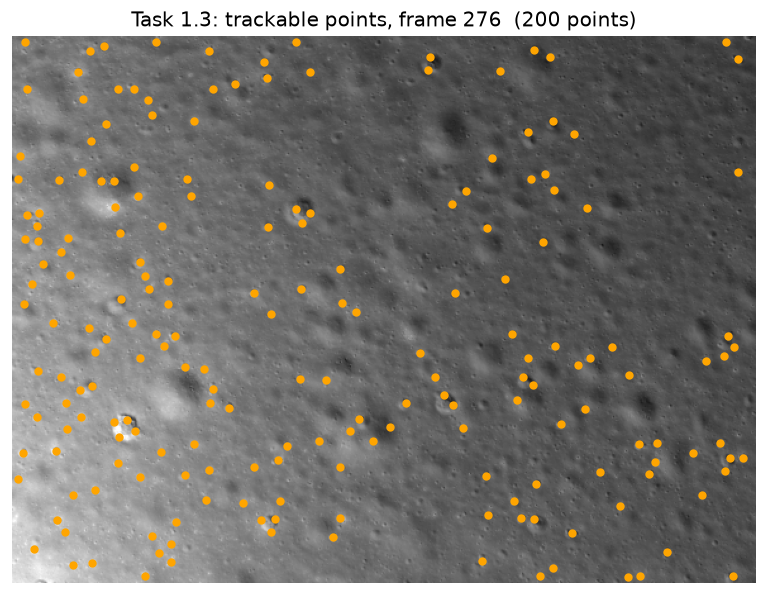

In [17]:
points = show_features(frame, select_features)

**(a)** What does the minimum distance between selected points prevent?

The minimum-distance constraint prevents selected feature points from clustering too closely together. Without this constraint, many of the strongest features could lie around the same corner or edge, resulting in redundant tracking information. Enforcing a minimum separation distributes features across the image, providing better spatial coverage and reducing the effect of losing multiple nearby features.

**(b)** What do the eigenvalues of $G$ look like on a flat patch, an edge and a corner?

The eigenvalues $\lambda_1$ and $\lambda_2$ of the structure tensor $G=A^TA$ describe the strength of intensity variation in two perpendicular directions.
- Flat patch: Both eigenvalues are small, $\lambda_1\approx\lambda_2\approx0$, because intensity changes very little in either direction.
- Edge: One eigenvalue is large and the other is small, $\lambda_1\approx0$, $\lambda_2\gg0$. Intensity changes strongly perpendicular to the edge but weakly along it.
- Corner: Both eigenvalues are large, $\lambda_1\gg0$ and $\lambda_2\gg0$, because intensity changes significantly in both directions.

**(c)** Why does a large $q$ mean a point is easy to track?

$$
q=\min(\lambda_1,\lambda_2)=\lambda_1,
$$
A large \(q\) indicates that intensity changes strongly in both independent directions, so the point's displacement can be estimated reliably in both horizontal and vertical directions. It also indicates that the structure tensor is less likely to be singular, making the Lucas–Kanade least-squares solution more stable. Thus, points with large \(q\) are preferred for tracking.